In [81]:
import yfinance as yf
import pandas as pd
import warnings
warnings.filterwarnings("ignore", category=pd.errors.Pandas4Warning)


# Projeto de Matemática Financeira e Análise de Investimentos

Este notebook reúne a exploração de Markowitz com WEG/Vulcabras e a análise da carteira definitiva de cinco ativos. O enunciado também exige triagem de ações, dois valuations por métodos distintos, otimização e backtest. A situação atual é:

| Etapa do enunciado | Estado no material lido | Próximo passo |
|---|---|---|
| 1. Seleção e triagem | Os cinco ativos foram escolhidos; a exploração de liquidez de WEG/Vulcabras é apenas didática. Ainda falta documentar critérios, setores, indicadores e tese de cada ativo numa tabela. | Construir a tabela de triagem e justificar os critérios de corte. |
| 2. Valuation | Não há cálculos de valor justo no notebook. | Você escolhe duas empresas e define premissas para DDM e FCFF/WACC antes de implementar. |
| 3. Markowitz | Há retornos, covariância, mínima variância, tangência e fronteira. As células finais antigas misturavam janelas; a seção abaixo passa a usar uma única calibração 2018–2020. | Revisar as saídas após executar de cima para baixo e interpretar as alocações. |
| 4. Backtest | Há uma comparação com Ibovespa e CDI para 2021–2025. O código combina retornos com pesos percentuais fixos, o que implica rebalanceamento diário. | Confirmar se essa é a política desejada ou escolher buy-and-hold antes do relatório final. |
| Entregáveis | Este notebook é parte do código reproduzível; o relatório técnico separado ainda não foi identificado na pasta. | Escrever o relatório após decisões e valuations, incluindo limitações e memorial de cálculo. |

Os ativos definitivos permanecem **EMBJ3.SA, ITUB3.SA, PETR4.SA, SUZB3.SA e VULC3.SA**. O PDF é a fonte dos requisitos; as células e saídas abaixo registram o que já foi feito, sem transformar as etapas ausentes em respostas prontas.


## Etapa 1 — seleção e triagem dos ativos

A seleção dos cinco ativos está definida e deve permanecer: EMBJ3.SA, ITUB3.SA, PETR4.SA, SUZB3.SA e VULC3.SA. O notebook ainda não contém a tabela sintética pedida no enunciado com critérios de corte, indicadores, setores e tese de seleção. Próximo passo: documentar esses critérios e demonstrar a diversidade setorial exigida pelo professor.


## Etapa 2 — valuation fundamentalista (a desenvolver)

O enunciado exige dois valuations distintos: DDM para uma empresa e FCFF/WACC, com projeção de dez anos e valor terminal, para outra. Não há modelos ou premissas de valuation neste notebook. As empresas e hipóteses econômicas permanecem decisões suas; esta seção não as escolhe nem as estima.


## Experimento didático: Markowitz com WEG e Vulcabras

Esta análise de dois ativos serviu para testar retornos, covariância, mínima variância e a forma da fronteira. Ela não representa a carteira definitiva e seus pesos não devem ser usados no backtest final.


In [82]:
tickers = ["WEGE3.SA", "VULC3.SA"]

dados = yf.download(
    tickers,
    start="2020-01-01",
    end="2026-11-12",
    interval="1d",
    auto_adjust=False,
    progress=False
)

print(dados.head())
print(dados.columns)


Price      Adj Close                Close                 High             \
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA   
Date                                                                        
2020-01-02  5.207672  15.458442  8.880052  17.620001  9.235254  17.735001   
2020-01-03  5.109306  15.261051  8.712317  17.395000  8.919519  17.625000   
2020-01-06  5.196099  15.300530  8.860318  17.440001  8.899785  17.549999   
2020-01-07  5.201887  15.418963  8.870185  17.575001  9.077386  17.584999   
2020-01-08  5.201887  14.835544  8.870185  16.910000  9.047786  17.610001   

Price            Low                 Open              Volume           
Ticker      VULC3.SA   WEGE3.SA  VULC3.SA   WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                    
2020-01-02  8.880052  17.360001  9.087253  17.450001  1189148  5876000  
2020-01-03  8.564316  17.334999  8.820851  17.500000  1930022  7345800  
2020-01-06  8.6531

In [83]:

precos = dados["Close"]
precos_ajustados = dados["Adj Close"]
volumes = dados["Volume"]

print("PREÇOS:")
print(precos.head())

print("\nVOLUMES:")
print(volumes.head())

print("\nVALORES AUSENTES:")
print(dados.isna().sum())


PREÇOS:
Ticker      VULC3.SA   WEGE3.SA
Date                           
2020-01-02  8.880052  17.620001
2020-01-03  8.712317  17.395000
2020-01-06  8.860318  17.440001
2020-01-07  8.870185  17.575001
2020-01-08  8.870185  16.910000

VOLUMES:
Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-02   1189148   5876000
2020-01-03   1930022   7345800
2020-01-06    742901   6366600
2020-01-07    552868   6303600
2020-01-08    699522   8153800

VALORES AUSENTES:
Price      Ticker  
Adj Close  VULC3.SA    0
           WEGE3.SA    0
Close      VULC3.SA    0
           WEGE3.SA    0
High       VULC3.SA    0
           WEGE3.SA    0
Low        VULC3.SA    0
           WEGE3.SA    0
Open       VULC3.SA    0
           WEGE3.SA    0
Volume     VULC3.SA    0
           WEGE3.SA    0
dtype: int64


In [84]:
volume_financeiro = precos * volumes
print(volume_financeiro.head())


Ticker          VULC3.SA      WEGE3.SA
Date                                  
2020-01-02  1.055970e+07  1.035351e+08
2020-01-03  1.681496e+07  1.277802e+08
2020-01-06  6.582339e+06  1.110335e+08
2020-01-07  4.904041e+06  1.107858e+08
2020-01-08  6.204889e+06  1.378808e+08


In [85]:

ultimos_252 = volume_financeiro.tail(252)

liquidez_media = ultimos_252.mean()

print(liquidez_media)


Ticker
VULC3.SA    2.622513e+07
WEGE3.SA    4.190004e+08
dtype: float64


In [86]:
print("Primeira data:", dados.index.min())
print("Última data:", dados.index.max())
print("Quantidade de pregões:", len(dados))

print("\nValores ausentes em Volume:")
print(volumes.isna().sum())

print("\nVolumes zerados:")
print((volumes == 0).sum())

Primeira data: 2020-01-02 00:00:00
Última data: 2026-11-11 00:00:00
Quantidade de pregões: 1709

Valores ausentes em Volume:
Ticker
VULC3.SA    0
WEGE3.SA    0
dtype: int64

Volumes zerados:
Ticker
VULC3.SA    0
WEGE3.SA    1
dtype: int64


In [87]:
# Identificar a data com volume zero
datas_zero = volumes.index[volumes["WEGE3.SA"] == 0]

print(datas_zero)

# Ver os dados completos nessas datas
print(dados.loc[datas_zero])

DatetimeIndex(['2022-09-26'], dtype='datetime64[s]', name='Date', freq=None)
Price      Adj Close                 Close                High           \
Ticker      VULC3.SA   WEGE3.SA   VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA   
Date                                                                      
2022-09-26  8.458341  27.793692  13.912081    30.57  14.405417    30.57   

Price             Low                Open            Volume           
Ticker       VULC3.SA WEGE3.SA   VULC3.SA WEGE3.SA VULC3.SA WEGE3.SA  
Date                                                                  
2022-09-26  13.912081    30.57  14.405417    30.57   314085        0  


In [88]:
dados.loc["2022-09-22":"2022-09-28", 
          [("Close", "WEGE3.SA"), ("Volume", "WEGE3.SA")]]

Price,Close,Volume
Ticker,WEGE3.SA,WEGE3.SA
Date,,
2022-09-22,31.010000,8889000
2022-09-23,30.570000,5895500
2022-09-26,30.570000,0
2022-09-27,30.049999,7256200
2022-09-28,30.320000,5869400


In [89]:
precos_ajustados_limpos = precos_ajustados.copy()

precos_ajustados_limpos.loc["2022-09-26", "WEGE3.SA"] = float("nan")

In [90]:
retornos = precos_ajustados_limpos.pct_change(fill_method=None)

In [91]:
print(retornos.loc["2022-09-22":"2022-09-29"])
print("\nValores ausentes:")
print(retornos.isna().sum())

Ticker      VULC3.SA  WEGE3.SA
Date                          
2022-09-22  0.035441 -0.005452
2022-09-23 -0.013423 -0.014189
2022-09-26 -0.040816       NaN
2022-09-27  0.004964       NaN
2022-09-28  0.005646  0.008985
2022-09-29 -0.001404 -0.005937

Valores ausentes:
Ticker
VULC3.SA    1
WEGE3.SA    3
dtype: int64


In [92]:
retornos_validos = retornos.dropna()

print(retornos_validos.head())
print("Observações válidas:", len(retornos_validos))

Ticker      VULC3.SA  WEGE3.SA
Date                          
2020-01-03 -0.018889 -0.012769
2020-01-06  0.016987  0.002587
2020-01-07  0.001114  0.007740
2020-01-08  0.000000 -0.037838
2020-01-09 -0.001113 -0.014784
Observações válidas: 1706


In [93]:
correlacao = retornos_validos.corr()

print(correlacao)

Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  1.000000  0.275916
WEGE3.SA  0.275916  1.000000


In [94]:
retornos_medios = retornos_validos.mean()

volatilidades = retornos_validos.std()

covariancias = retornos_validos.cov()

print("Retornos médios diários:")
print(retornos_medios)

print("\nVolatilidades diárias:")
print(volatilidades)

print("\nMatriz de covariância:")
print(covariancias)

Retornos médios diários:
Ticker
VULC3.SA    0.000833
WEGE3.SA    0.000979
dtype: float64

Volatilidades diárias:
Ticker
VULC3.SA    0.025400
WEGE3.SA    0.022895
dtype: float64

Matriz de covariância:
Ticker    VULC3.SA  WEGE3.SA
Ticker                      
VULC3.SA  0.000645  0.000160
WEGE3.SA  0.000160  0.000524


In [95]:
import numpy as np

# Ordem: VULC3, WEGE3
ativos = ["VULC3.SA", "WEGE3.SA"]

mu = retornos_validos[ativos].mean()
Sigma = retornos_validos[ativos].cov()

# Elementos da matriz de covariância
var1 = Sigma.iloc[0, 0]
var2 = Sigma.iloc[1, 1]
cov12 = Sigma.iloc[0, 1]

# Pesos da carteira de mínima variância
w1 = (var2 - cov12) / (var1 + var2 - 2 * cov12)
w1 = np.clip(w1, 0, 1)  # Sem vendas a descoberto
w2 = 1 - w1

w = np.array([w1, w2])

# Retorno esperado e volatilidade da carteira
retorno_carteira = w @ mu.to_numpy()
variancia_carteira = w @ Sigma.to_numpy() @ w
volatilidade_carteira = np.sqrt(variancia_carteira)

print(f"Peso Vulcabras: {w1:.2%}")
print(f"Peso WEG: {w2:.2%}")

print(f"\nRetorno médio diário: {retorno_carteira:.4%}")
print(f"Volatilidade diária: {volatilidade_carteira:.4%}")

print(f"\nVolatilidade Vulcabras: {np.sqrt(var1):.4%}")
print(f"Volatilidade WEG: {np.sqrt(var2):.4%}")

Peso Vulcabras: 42.87%
Peso WEG: 57.13%

Retorno médio diário: 0.0917%
Volatilidade diária: 1.9190%

Volatilidade Vulcabras: 2.5400%
Volatilidade WEG: 2.2895%


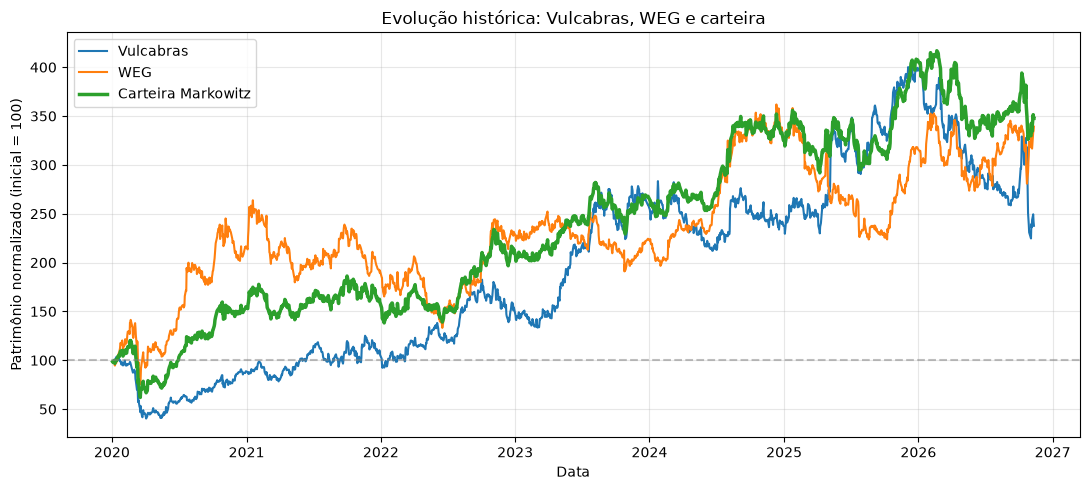

In [96]:

import matplotlib.pyplot as plt
import pandas as pd

# Retornos diários das duas ações
retornos_ativos = retornos_validos[["VULC3.SA", "WEGE3.SA"]]

# Retorno diário da carteira com pesos constantes
retornos_carteira = (
    w1 * retornos_ativos["VULC3.SA"]
    + w2 * retornos_ativos["WEGE3.SA"]
)

# Evolução acumulada começando em 100
evolucao = (1 + retornos_ativos).cumprod() * 100
evolucao["Carteira Markowitz"] = (
    (1 + retornos_carteira).cumprod() * 100
)

# Gráfico
plt.figure(figsize=(11, 5))

plt.plot(evolucao.index, evolucao["VULC3.SA"],
         label="Vulcabras")

plt.plot(evolucao.index, evolucao["WEGE3.SA"],
         label="WEG")

plt.plot(evolucao.index, evolucao["Carteira Markowitz"],
         label="Carteira Markowitz", linewidth=2.5)

plt.axhline(100, linestyle="--", color="gray", alpha=0.5)

plt.title("Evolução histórica: Vulcabras, WEG e carteira")
plt.xlabel("Data")
plt.ylabel("Patrimônio normalizado (inicial = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


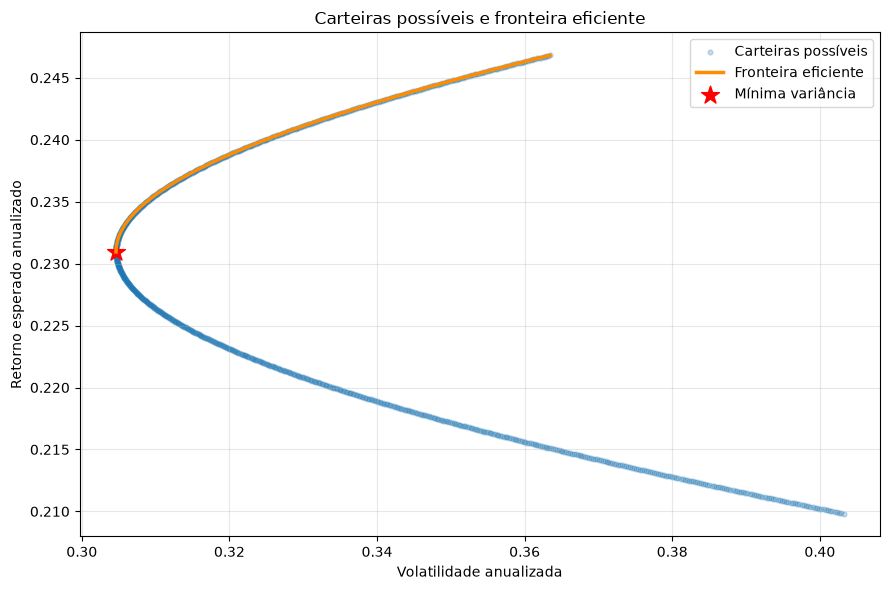

Peso de VULC3.SA na carteira de mínima variância: 42.90%
Peso de WEGE3.SA na carteira de mínima variância: 57.10%


In [97]:
# Fronteira eficiente para os dois ativos do teste
# Pressupõe que as células anteriores já criaram `retornos_validos` e `ativos`.
import numpy as np
import matplotlib.pyplot as plt

retornos_dois_ativos = retornos_validos[ativos].dropna()
mu_diario = retornos_dois_ativos.mean().to_numpy()
cov_diaria = retornos_dois_ativos.cov().to_numpy()

# Variamos o peso do primeiro ativo; o peso do segundo é o que falta para 100%.
peso_1 = np.linspace(0, 1, 1001)
pesos = np.column_stack([peso_1, 1 - peso_1])

retornos_diarios_carteiras = pesos @ mu_diario
variancias_diarias = np.einsum('ij,jk,ik->i', pesos, cov_diaria, pesos)
volatilidades_diarias = np.sqrt(np.maximum(variancias_diarias, 0))

# Anualização aproximada para dados diários (252 pregões por ano).
retornos_anuais = retornos_diarios_carteiras * 252
volatilidades_anuais = volatilidades_diarias * np.sqrt(252)

# Destaca os pontos não dominados: não existe outra carteira com risco menor
# ou igual e retorno maior ou igual.
ordem = np.lexsort((-retornos_anuais, volatilidades_anuais))
indices_eficientes = []
maior_retorno_ate_agora = -np.inf
for i in ordem:
    if retornos_anuais[i] > maior_retorno_ate_agora + 1e-12:
        indices_eficientes.append(i)
        maior_retorno_ate_agora = retornos_anuais[i]

indices_eficientes = np.array(indices_eficientes)
ordem_fronteira = indices_eficientes[np.argsort(volatilidades_anuais[indices_eficientes])]

# Carteira de menor volatilidade entre as combinações testadas.
indice_min_variancia = np.argmin(volatilidades_anuais)

plt.figure(figsize=(9, 6))
plt.scatter(volatilidades_anuais, retornos_anuais,
            s=12, alpha=0.25, label='Carteiras possíveis')
plt.plot(volatilidades_anuais[ordem_fronteira],
         retornos_anuais[ordem_fronteira],
         color='darkorange', linewidth=2.5, label='Fronteira eficiente')
plt.scatter(volatilidades_anuais[indice_min_variancia],
            retornos_anuais[indice_min_variancia],
            color='red', marker='*', s=180, label='Mínima variância')
plt.xlabel('Volatilidade anualizada')
plt.ylabel('Retorno esperado anualizado')
plt.title('Carteiras possíveis e fronteira eficiente')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Peso de {ativos[0]} na carteira de mínima variância: {pesos[indice_min_variancia, 0]:.2%}")
print(f"Peso de {ativos[1]} na carteira de mínima variância: {pesos[indice_min_variancia, 1]:.2%}")


## Carteira definitiva — Etapa 3: cinco ativos

A carteira e os tickers são mantidos conforme sua decisão: EMBJ3.SA, ITUB3.SA, PETR4.SA, SUZB3.SA e VULC3.SA. A janela de estimação é 2018–2020; o histórico anterior aparece somente na auditoria de qualidade.


In [98]:
# 1. Coleta, qualidade dos dados e definição das janelas
import numpy as np
import requests
from scipy.optimize import minimize

ativos = ["EMBJ3.SA", "ITUB3.SA", "PETR4.SA", "SUZB3.SA", "VULC3.SA"]
# As estimativas da carteira usam exclusivamente 2018–2020. A descarga anterior a 2018
# fica separada para investigar qualidade histórica, sem reconstruir SUZB3.
data_inicio_download = "2000-01-01"  # histórico amplo apenas para auditoria de dados
data_inicio_calibracao = "2018-01-01"
data_fim_calibracao_exclusivo = "2021-01-01"  # até o último pregão de 2020
data_inicio_teste = "2021-01-01"
data_fim_teste_exclusivo = "2026-01-01"  # cinco anos-calendário: 2021–2025
data_fim = data_fim_teste_exclusivo

# Mantém as três séries originais para auditoria.
dados_historicos = yf.download(
    ativos, start=data_inicio_download, end=data_fim, interval="1d",
    auto_adjust=False, progress=False, group_by="column",
)
precos_fechamento = dados_historicos["Close"].reindex(columns=ativos)
precos_ajustados = dados_historicos["Adj Close"].reindex(columns=ativos)
volumes_carteira = dados_historicos["Volume"].reindex(columns=ativos)
precos_carteira = precos_ajustados.copy()  # proxy de retorno total do provedor

# CDI diário do Banco Central (SGS 12), convertido de % para decimal.
limites_cdi = [("01/01/2000", "31/12/2009"), ("01/01/2010", "31/12/2019"), ("01/01/2020", "31/12/2025")]
tabelas_cdi = []
for data_inicial_cdi, data_final_cdi in limites_cdi:
    resposta_cdi = requests.get(
        "https://api.bcb.gov.br/dados/serie/bcdata.sgs.12/dados",
        params={"formato": "json", "dataInicial": data_inicial_cdi, "dataFinal": data_final_cdi}, timeout=30,
    )
    resposta_cdi.raise_for_status()
    tabelas_cdi.extend(resposta_cdi.json())
tabela_cdi = pd.DataFrame(tabelas_cdi).drop_duplicates(subset="data", keep="last")
tabela_cdi["data"] = pd.to_datetime(tabela_cdi["data"], dayfirst=True)
tabela_cdi["valor"] = pd.to_numeric(tabela_cdi["valor"], errors="coerce")
serie_cdi = (tabela_cdi.set_index("data")["valor"] / 100).sort_index().rename("CDI")

# Diagnóstico preserva as séries originais. Volume zero é tratado como ausência
# de negociação no modelo, sem apagar nem sobrescrever a coleta original.
qualidade = pd.DataFrame({
    "primeiro_preco": precos_carteira.apply(lambda s: s.first_valid_index()),
    "faltantes_preco_ajustado": precos_ajustados.isna().sum(),
    "faltantes_preco_fechamento": precos_fechamento.isna().sum(),
    "volumes_zero": volumes_carteira.eq(0).sum(),
    "precos_repetidos_consecutivos": precos_carteira.diff().eq(0).sum(),
})
print("Qualidade inicial por ativo:")
display(qualidade)

# Calcula retornos antes de excluir linhas incompletas, evitando retornos de vários
# pregões tratados como diários. Política explícita: zero volume invalida o preço do dia
# e interrompe a série desse ativo. Mude após revisar a confiabilidade do volume do Yahoo.
excluir_volume_zero = True
precos_modelagem = precos_carteira.mask(volumes_carteira.eq(0)) if excluir_volume_zero else precos_carteira.copy()
retornos_diarios_todos = precos_modelagem.pct_change(fill_method=None)
retornos_diarios_todos = retornos_diarios_todos.replace([np.inf, -np.inf], np.nan)
retornos_completos = retornos_diarios_todos.dropna(how="any")
retornos_calibracao = retornos_completos.loc[data_inicio_calibracao:data_fim_calibracao_exclusivo].copy()
retornos_teste = retornos_completos.loc[data_inicio_teste:data_fim_teste_exclusivo].copy()
if retornos_calibracao.empty:
    raise ValueError("Não há retornos completos dos cinco ativos na calibração.")
if retornos_teste.empty:
    raise ValueError("Não há retornos completos dos cinco ativos no teste.")
print("Calibração solicitada: 2018-01-01 a 2020-12-31")
print("Calibração efetiva:", retornos_calibracao.index.min().date(), "a", retornos_calibracao.index.max().date())
print("Teste fixo:", retornos_teste.index.min().date(), "a", retornos_teste.index.max().date())
print("Pregões completos — calibração:", len(retornos_calibracao), "| teste:", len(retornos_teste))
print("Datas sem retorno completo — calibração:", retornos_diarios_todos.loc[data_inicio_calibracao:data_fim_calibracao_exclusivo].isna().any(axis=1).sum(),
      "| teste:", retornos_diarios_todos.loc[data_inicio_teste:data_fim_teste_exclusivo].isna().any(axis=1).sum())
print("Liquidez indicativa (Close × Volume), últimos 252 pregões disponíveis:")
volume_financeiro_carteira = precos_fechamento * volumes_carteira
display(volume_financeiro_carteira.tail(252).mean().sort_values(ascending=False))


Qualidade inicial por ativo:


,primeiro_preco,faltantes_preco_ajustado,faltantes_preco_fechamento,volumes_zero,precos_repetidos_consecutivos
Ticker,,,,,
EMBJ3.SA,2000-01-03,0,0,124,283
ITUB3.SA,2000-01-03,0,0,430,1088
PETR4.SA,2000-01-03,0,0,146,233
SUZB3.SA,2004-08-05,1198,1198,3310,3301
VULC3.SA,2000-02-25,39,39,2952,3303


Calibração solicitada: 2018-01-01 a 2020-12-31
Calibração efetiva: 2018-01-03 a 2020-12-30
Teste fixo: 2021-01-04 a 2025-12-30
Pregões completos — calibração: 739 | teste: 1244
Datas sem retorno completo — calibração: 3 | teste: 2
Liquidez indicativa (Close × Volume), últimos 252 pregões disponíveis:


Ticker
PETR4.SA    1.141264e+09
EMBJ3.SA    4.110395e+08
SUZB3.SA    2.935903e+08
ITUB3.SA    2.237951e+07
VULC3.SA    1.706587e+07
dtype: float64

### Qualidade histórica e eventos suspeitos (fora da calibração)

A série anterior a 2018 é mantida apenas para auditoria; não participa das estimativas da carteira. Os saltos reportados são inspecionados em `Close`, `Adj Close` e volume, sem winsorização. Na extração salva do Yahoo: VULC3 em 25/10/2004 passa de Close 4.500 para 17.900 (Adj Close 2.453,50 para 9.759,49), mas o preço anterior foi repetido com volume zero; o +297,8% não é seguramente um retorno de um pregão. Em 07/02/2007, Close e Adj Close sobem exatamente 100 vezes, com volume 10 e preços repetidos em seguida. Foi localizado registro de grupamento VULC3 de 100:1 efetivado em 14/05/2007; por ser posterior, ele não explica diretamente o salto de fevereiro ([comunicado reproduzido pela InfoMoney](https://www.infomoney.com.br/mercados/vulcabras-informa-sobre-distribuicao-de-dividendos-e-grupamento-das-acoes/)).

Para SUZB3, Close cai de 5,936 para 0,800 em 18/01/2007 e sobe de 0,800 para 16,00 em 08/05/2007. Os registros exibidos têm volume zero e preços repetidos. Não foi confirmada uma ação societária que explique os saltos; a origem pode ser dado/ajuste do provedor ou cotações sem negociação. O notebook não tenta reconstruir a série antiga.

Na janela efetivamente usada, 2018–2020, os dados completos fornecidos no notebook têm 739 retornos comuns, de 03/01/2018 a 30/12/2020. A regra `excluir_volume_zero = True` preserva os dados originais e evita atribuir variação desde uma cotação carregada a um único pregão. É uma hipótese de tratamento, dependente da qualidade do campo Volume do Yahoo, e deve ser informada no relatório.


In [99]:
# Close, Adj Close e Volume nos quatro eventos reportados.
eventos_suspeitos = {"VULC3.SA": ["2004-10-25", "2007-02-07"], "SUZB3.SA": ["2007-01-18", "2007-05-08"]}
for ativo, datas in eventos_suspeitos.items():
    for data_evento in datas:
        inicio = (pd.Timestamp(data_evento) - pd.Timedelta(days=4)).strftime("%Y-%m-%d")
        fim = (pd.Timestamp(data_evento) + pd.Timedelta(days=4)).strftime("%Y-%m-%d")
        print(f"\n{ativo} — evento reportado em {data_evento}")
        janela = pd.DataFrame({"Close": precos_fechamento[ativo], "Adj Close": precos_ajustados[ativo],
                               "Volume": volumes_carteira[ativo], "Retorno Adj Close": retornos_diarios_todos[ativo]}).loc[inicio:fim]
        display(janela)
print("\nMaiores retornos absolutos da calibração (diagnóstico, sem exclusão):")
for ativo in ativos:
    display(retornos_calibracao[ativo].abs().nlargest(8).rename(ativo))



VULC3.SA — evento reportado em 2004-10-25


,Close,Adj Close,Volume,Retorno Adj Close
Date,,,,
2004-10-21,4500.0,2453.502686,0.0,NaN
2004-10-22,4500.0,2453.502686,0.0,NaN
2004-10-25,17900.0,9759.488281,9210.0,NaN
2004-10-26,17900.0,9759.488281,0.0,NaN
2004-10-27,30000.0,16356.684570,120.0,NaN
2004-10-28,38000.0,20718.462891,70.0,0.266666
2004-10-29,45000.0,24535.023438,40.0,0.184211



VULC3.SA — evento reportado em 2007-02-07


,Close,Adj Close,Volume,Retorno Adj Close
Date,,,,
2007-02-05,2100.0,1144.967651,0.0,NaN
2007-02-06,2100.0,1144.967651,0.0,NaN
2007-02-07,210000.0,114496.789062,10.0,NaN
2007-02-08,210000.0,114496.789062,10.0,0.0
2007-02-09,210000.0,114496.789062,10.0,0.0



SUZB3.SA — evento reportado em 2007-01-18


,Close,Adj Close,Volume,Retorno Adj Close
Date,,,,
2007-01-15,5.936,4.506152,0.0,NaN
2007-01-16,5.936,4.506152,0.0,NaN
2007-01-17,5.936,4.506152,0.0,NaN
2007-01-18,0.800,0.607298,0.0,NaN
2007-01-19,0.800,0.607298,0.0,NaN
2007-01-22,0.800,0.607298,0.0,NaN


... (4 outputs left out)

Date
2020-03-13    0.110330
2020-03-12    0.100791
2020-03-16    0.099366
2020-03-18    0.085330
2020-04-28    0.084419
2020-11-09    0.067789
2020-03-23    0.066351
2019-01-02    0.064092
Name: ITUB3.SA, dtype: float64

Date
2020-03-09    0.296978
2020-03-13    0.222222
2020-03-12    0.205047
2020-03-24    0.152174
2020-03-16    0.150000
2018-06-01    0.148578
2018-05-28    0.145960
2018-05-29    0.141336
Name: PETR4.SA, dtype: float64

Date
2018-03-16    0.217949
2020-03-27    0.171836
2020-03-12    0.161308
2020-03-18    0.120714
2020-03-19    0.110073
2020-03-16    0.101647
2018-06-08    0.095450
2020-03-04    0.090135
Name: SUZB3.SA, dtype: float64

Date
2020-03-12    0.182251
2020-03-19    0.135071
2020-03-23    0.134396
2018-08-20    0.124000
2020-03-16    0.119403
2020-05-27    0.116389
2020-03-09    0.111582
2020-10-28    0.108781
Name: VULC3.SA, dtype: float64

### Disponibilidade e cotações sem negociação

A tabela conta retornos disponíveis por ano. O trecho de 2017 mostra por que não usamos a história anterior de SUZB3 para estimação.


In [100]:
# Contagem de retornos diários informados por ativo e ano.
# Ajuda a localizar trechos em que o Yahoo devolve preços repetidos sem volume.
disponibilidade = retornos_diarios_todos.notna().groupby(retornos_diarios_todos.index.year).sum()
print(disponibilidade.loc[2015:2020])


Ticker  EMBJ3.SA  ITUB3.SA  PETR4.SA  SUZB3.SA  VULC3.SA
Date                                                    
2015         246       246       246         0       102
2016         249       249       249         0       218
2017         237       235       237        28       237
2018         243       243       243       243       243
2019         248       248       248       248       248
2020         248       248       248       248       248


In [101]:
# Exemplo da série SUZB3 em 2017: cotações repetidas e volume zero.
# É diagnóstico histórico, não parte da calibração 2018–2020.
print(dados_historicos.loc[
    "2017-01-01":"2018-01-31",
    [("Close", "SUZB3.SA"), ("Volume", "SUZB3.SA")]
].head(35))


Price         Close   Volume
Ticker     SUZB3.SA SUZB3.SA
Date                        
2017-01-02    20.01      0.0
2017-01-03    20.01      0.0
2017-01-04    20.01      0.0
2017-01-05    20.01      0.0
2017-01-06    20.01      0.0
2017-01-09    20.01      0.0
2017-01-10    20.01      0.0
2017-01-11    20.01      0.0
2017-01-12    20.01      0.0
2017-01-13    20.01      0.0
2017-01-16    20.01      0.0
2017-01-17    20.01      0.0
2017-01-18    20.01      0.0
2017-01-19    20.01      0.0
2017-01-20    20.01      0.0
2017-01-23    20.01      0.0
2017-01-24    20.01      0.0
2017-01-26    20.01      0.0
2017-01-27    20.01      0.0
2017-01-30    20.01      0.0
2017-01-31    20.01      0.0
2017-02-01    20.01      0.0
2017-02-02    20.01      0.0
2017-02-03    20.01      0.0
2017-02-06    20.01      0.0
2017-02-07    20.01      0.0
2017-02-08    20.01      0.0
2017-02-09    20.01      0.0
2017-02-10    20.01      0.0
2017-02-13    20.01      0.0
2017-02-14    20.01      0.0
2017-02-15    

### Estimação dos parâmetros de Markowitz

Calculamos a média amostral dos retornos diários e a covariância amostral. A covariância mede risco conjunto; a diagonal contém variâncias e os termos fora da diagonal, covariâncias. A matriz deve ser simétrica e semidefinida positiva.


In [102]:
# Estimação do vetor de médias e da covariância amostral (frequência diária).
# São os parâmetros de risco/retorno de Markowitz, calculados somente em 2018–2020.
retorno_medio_diario = retornos_calibracao.mean()
volatilidade_diaria = retornos_calibracao.std(ddof=1)
matriz_covariancia_diaria = retornos_calibracao.cov()
matriz_correlacao = retornos_calibracao.corr()
print("Retornos médios diários:")
display(retorno_medio_diario.to_frame("Retorno médio diário"))
print("Volatilidades diárias amostrais:")
display(volatilidade_diaria.to_frame("Volatilidade diária"))
print("Matriz de correlação:")
display(matriz_correlacao)
print("Matriz de covariância diária:")
display(matriz_covariancia_diaria)
cov_np = matriz_covariancia_diaria.to_numpy(dtype=float)
assert np.all(np.isfinite(cov_np)), "Covariância contém valores não finitos."
assert np.allclose(cov_np, cov_np.T, atol=1e-12), "Covariância não é simétrica."
autovalores_cov = np.linalg.eigvalsh((cov_np + cov_np.T) / 2)
print("Menor autovalor da covariância diária:", autovalores_cov.min())
if autovalores_cov.min() < -1e-10:
    raise ValueError("Covariância não é semidefinida positiva dentro da tolerância.")


Retornos médios diários:


,Retorno médio diário
Ticker,
EMBJ3.SA,-0.000602
ITUB3.SA,0.000540
PETR4.SA,0.001354
SUZB3.SA,0.002050
VULC3.SA,0.000177


Volatilidades diárias amostrais:


,Volatilidade diária
Ticker,
EMBJ3.SA,0.032222
ITUB3.SA,0.019870
PETR4.SA,0.033091
SUZB3.SA,0.030813
VULC3.SA,0.028643


Matriz de correlação:


Ticker,EMBJ3.SA,ITUB3.SA,PETR4.SA,SUZB3.SA,VULC3.SA
Ticker,,,,,
EMBJ3.SA,1.000000,0.559209,0.515255,0.154033,0.466719
ITUB3.SA,0.559209,1.000000,0.594487,0.046403,0.539847
PETR4.SA,0.515255,0.594487,1.000000,0.164016,0.448981
SUZB3.SA,0.154033,0.046403,0.164016,1.000000,0.080825
VULC3.SA,0.466719,0.539847,0.448981,0.080825,1.000000


Matriz de covariância diária:


Ticker,EMBJ3.SA,ITUB3.SA,PETR4.SA,SUZB3.SA,VULC3.SA
Ticker,,,,,
EMBJ3.SA,0.001038,0.000358,0.000549,0.000153,0.000431
ITUB3.SA,0.000358,0.000395,0.000391,0.000028,0.000307
PETR4.SA,0.000549,0.000391,0.001095,0.000167,0.000426
SUZB3.SA,0.000153,0.000028,0.000167,0.000949,0.000071
VULC3.SA,0.000431,0.000307,0.000426,0.000071,0.000820


Menor autovalor da covariância diária: 0.00017737914568907346


### Carteira de mínima variância

Escolhe os pesos long-only que minimizam a variância da carteira. A soma dos pesos é 1. O retorno esperado serve para interpretar o resultado, mas não entra no objetivo de mínima variância.


In [103]:
# Carteira de mínima variância — problema convexo com pesos long-only.
# Usa média e covariância calculadas acima; o retorno esperado não entra no objetivo.
retornos_anuais_ativos = retorno_medio_diario * 252
covariancia_anual = matriz_covariancia_diaria * 252
n_ativos = len(ativos)
pesos_iguais = np.repeat(1 / n_ativos, n_ativos)
limites_pesos = [(0.0, 1.0)] * n_ativos
restricao_soma = {"type": "eq", "fun": lambda pesos: np.sum(pesos) - 1}

def volatilidade_anualizada(pesos):
    return float(np.sqrt(pesos @ covariancia_anual.to_numpy() @ pesos))

def validar_pesos(pesos, nome):
    if not np.isclose(np.sum(pesos), 1.0, atol=1e-7):
        raise ValueError(f"{nome}: pesos não somam 1.")
    if np.any(np.asarray(pesos) < -1e-8) or np.any(np.asarray(pesos) > 1 + 1e-8):
        raise ValueError(f"{nome}: peso fora de [0, 1].")

resultado_min_variancia = minimize(
    lambda w: w @ covariancia_anual.to_numpy() @ w,
    pesos_iguais, method="SLSQP", bounds=limites_pesos,
    constraints=[restricao_soma], options={"maxiter": 2000, "ftol": 1e-12},
)
if not resultado_min_variancia.success:
    raise RuntimeError(f"Mínima variância falhou: {resultado_min_variancia.message}")
pesos_min_variancia = resultado_min_variancia.x
validar_pesos(pesos_min_variancia, "Mínima variância")
print("Pesos da carteira de mínima variância:")
display(pd.DataFrame({"Peso (%)": 100 * pesos_min_variancia}, index=ativos).round(4))
print(f"Volatilidade mínima diária: {np.sqrt(pesos_min_variancia @ matriz_covariancia_diaria.to_numpy() @ pesos_min_variancia):.4%}")
print(f"Volatilidade mínima anualizada: {volatilidade_anualizada(pesos_min_variancia):.4%}")


Pesos da carteira de mínima variância:


,Peso (%)
EMBJ3.SA,0.0000
ITUB3.SA,63.8272
PETR4.SA,0.0000
SUZB3.SA,27.5897
VULC3.SA,8.5831


Volatilidade mínima diária: 1.6918%
Volatilidade mínima anualizada: 26.8558%


#### Conferência: Itaú + Suzano e mínima variância

A carteira 50/50 é admissível. Portanto, a solução de mínima variância calculada com a mesma matriz de covariância precisa ter volatilidade diária menor ou igual à dela. Esta célula usa as variáveis reais da otimização e inclui uma asserção.


In [104]:
# Experimento Itaú + Suzano: compara volatilidades diárias na mesma matriz da otimização.
# `Sigma` anterior era uma variável criada por células exploratórias; usamos a matriz atual diretamente.
risco_itau = np.sqrt(matriz_covariancia_diaria.loc["ITUB3.SA", "ITUB3.SA"])
var_itau = matriz_covariancia_diaria.loc["ITUB3.SA", "ITUB3.SA"]
var_suzano = matriz_covariancia_diaria.loc["SUZB3.SA", "SUZB3.SA"]
cov_itau_suzano = matriz_covariancia_diaria.loc["ITUB3.SA", "SUZB3.SA"]
risco_dupla = np.sqrt(0.25 * var_itau + 0.25 * var_suzano + 0.5 * cov_itau_suzano)

# Os pesos reais estão em `pesos_min_variancia`; a volatilidade é calculada pela matriz
# da mesma calibração em `matriz_covariancia_diaria`. Não existem `vol_min` ou `pesos_min`.
print(f"100% Itaú: {risco_itau:.4%}")
print(f"50% Itaú / 50% Suzano: {risco_dupla:.4%}")
print(f"Mínima variância (pesos_min_variancia): {np.sqrt(pesos_min_variancia @ matriz_covariancia_diaria.to_numpy() @ pesos_min_variancia):.4%}")
print("Pesos usados:")
display(pd.Series(pesos_min_variancia, index=ativos, name="Peso"))
assert np.sqrt(pesos_min_variancia @ matriz_covariancia_diaria.to_numpy() @ pesos_min_variancia) <= risco_dupla + 1e-10,     "A solução de mínima variância deve ser pelo menos tão boa quanto a carteira admissível 50/50."


100% Itaú: 1.9870%
50% Itaú / 50% Suzano: 1.8715%
Mínima variância (pesos_min_variancia): 1.6918%
Pesos usados:


EMBJ3.SA    0.000000e+00
ITUB3.SA    6.382719e-01
PETR4.SA    3.564844e-18
SUZB3.SA    2.758972e-01
VULC3.SA    8.583092e-02
Name: Peso, dtype: float64

### Carteira de tangência — máximo Índice de Sharpe

Maximiza o retorno esperado excedente ao CDI por unidade de risco. A otimização usa apenas calibração e compara várias inicializações; não usa o backtest para escolher os pesos.


In [105]:
# Carteira de tangência — maximiza o Sharpe esperado na calibração.
# CDI diário é convertido para a mesma aproximação anual usada nos retornos (média × 252).
cdi_calibracao = serie_cdi.reindex(retornos_calibracao.index).dropna()
if cdi_calibracao.empty:
    raise ValueError("Não há CDI alinhado à janela de calibração.")
taxa_livre_risco_anual = float(cdi_calibracao.mean() * 252)

def menos_sharpe(pesos):
    retorno = float(pesos @ retornos_anuais_ativos.to_numpy())
    risco = volatilidade_anualizada(pesos)
    return -(retorno - taxa_livre_risco_anual) / risco

# Várias inicializações reduzem a dependência de um único ponto inicial no SLSQP.
inicios_sharpe = [pesos_iguais, pesos_min_variancia] + [np.eye(n_ativos)[i] for i in range(n_ativos)]
resultados_sharpe = [minimize(menos_sharpe, inicio, method="SLSQP", bounds=limites_pesos,
    constraints=[restricao_soma], options={"maxiter": 2000, "ftol": 1e-12}) for inicio in inicios_sharpe]
resultados_sharpe_validos = [r for r in resultados_sharpe if r.success]
if not resultados_sharpe_validos:
    raise RuntimeError("Máximo Sharpe falhou em todas as inicializações.")
resultado_max_sharpe = min(resultados_sharpe_validos, key=lambda r: r.fun)
pesos_max_sharpe = resultado_max_sharpe.x
validar_pesos(pesos_max_sharpe, "Máximo Sharpe")
retorno_tangencia_anual = float(pesos_max_sharpe @ retornos_anuais_ativos.to_numpy())
print("CDI médio diário × 252:", f"{taxa_livre_risco_anual:.4%}")
print("Inicializações SLSQP bem-sucedidas:", len(resultados_sharpe_validos), "/", len(inicios_sharpe))
display(pd.DataFrame({"Peso (%)": 100 * pesos_max_sharpe}, index=ativos).round(4))
print(f"Retorno esperado anualizado: {retorno_tangencia_anual:.4%}")
print(f"Volatilidade anualizada: {volatilidade_anualizada(pesos_max_sharpe):.4%}")
print(f"Sharpe esperado na calibração: {(retorno_tangencia_anual-taxa_livre_risco_anual)/volatilidade_anualizada(pesos_max_sharpe):.4f}")


CDI médio diário × 252: 4.9214%
Inicializações SLSQP bem-sucedidas: 7 / 7


,Peso (%)
EMBJ3.SA,0.0000
ITUB3.SA,0.0000
PETR4.SA,30.0817
SUZB3.SA,69.9183
VULC3.SA,0.0000


Retorno esperado anualizado: 46.3871%
Volatilidade anualizada: 39.9576%
Sharpe esperado na calibração: 1.0377


### Fronteira eficiente

Para cada retorno-alvo factível, o código minimiza a variância sob as mesmas restrições long-only. A parte abaixo da carteira global de mínima variância é descartada por ser dominada: para aquele risco há carteira com retorno superior.


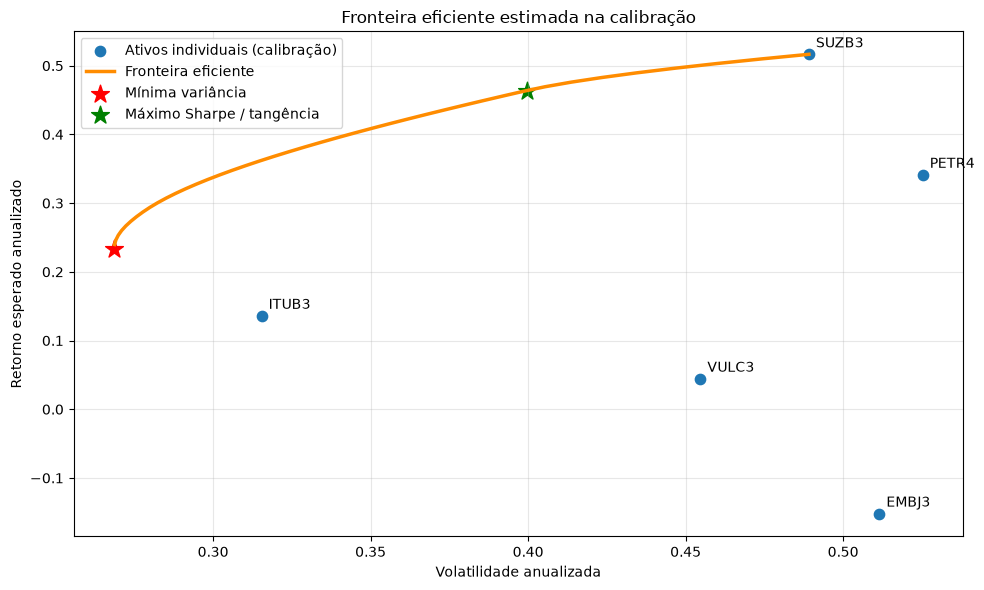

In [106]:
# Fronteira eficiente: para cada retorno-alvo, minimiza a variância sujeita a pesos long-only.
import matplotlib.pyplot as plt

retornos_alvo = np.linspace(retornos_anuais_ativos.min(), retornos_anuais_ativos.max(), 100)
pontos_fronteira = []
for retorno_alvo in retornos_alvo:
    restricoes = [
        restricao_soma,
        {"type": "eq", "fun": lambda pesos, alvo=retorno_alvo: pesos @ retornos_anuais_ativos.to_numpy() - alvo},
    ]
    resultado = minimize(
        lambda pesos: pesos @ covariancia_anual.to_numpy() @ pesos,
        pesos_iguais,
        method="SLSQP",
        bounds=limites_pesos,
        constraints=restricoes,
        options={"maxiter": 2000, "ftol": 1e-12},
    )
    if resultado.success:
        validar_pesos(resultado.x, "Ponto da fronteira")
        pontos_fronteira.append((volatilidade_anualizada(resultado.x), float(resultado.x @ retornos_anuais_ativos.to_numpy())))

fronteira = np.asarray(pontos_fronteira)
risco_minimo = volatilidade_anualizada(pesos_min_variancia)
retorno_minimo = float(pesos_min_variancia @ retornos_anuais_ativos.to_numpy())
if len(fronteira):
    fronteira = fronteira[fronteira[:, 1] >= retorno_minimo - 1e-10]
risco_sharpe = volatilidade_anualizada(pesos_max_sharpe)
retorno_sharpe = float(pesos_max_sharpe @ retornos_anuais_ativos.to_numpy())

plt.figure(figsize=(10, 6))
plt.scatter(
    np.sqrt(np.diag(covariancia_anual.to_numpy())),
    retornos_anuais_ativos,
    label="Ativos individuais (calibração)",
    s=55,
)
for ativo, risco, retorno in zip(ativos, np.sqrt(np.diag(covariancia_anual.to_numpy())), retornos_anuais_ativos):
    plt.annotate(ativo.replace(".SA", ""), (risco, retorno), xytext=(5, 5), textcoords="offset points")
if len(fronteira):
    ordem = np.argsort(fronteira[:, 0])
    plt.plot(fronteira[ordem, 0], fronteira[ordem, 1], color="darkorange", linewidth=2.5, label="Fronteira eficiente")
plt.scatter(risco_minimo, retorno_minimo, color="red", marker="*", s=180, label="Mínima variância")
plt.scatter(risco_sharpe, retorno_sharpe, color="green", marker="*", s=180, label="Máximo Sharpe / tangência")
plt.xlabel("Volatilidade anualizada")
plt.ylabel("Retorno esperado anualizado")
plt.title("Fronteira eficiente estimada na calibração")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



### Backtesting fora da amostra

Os pesos definidos na calibração permanecem congelados como parâmetros até o final do teste. O código existente aplica pesos percentuais constantes em cada pregão, o que equivale a rebalanceamento diário. Buy-and-hold é alternativa diferente e ainda requer sua decisão.


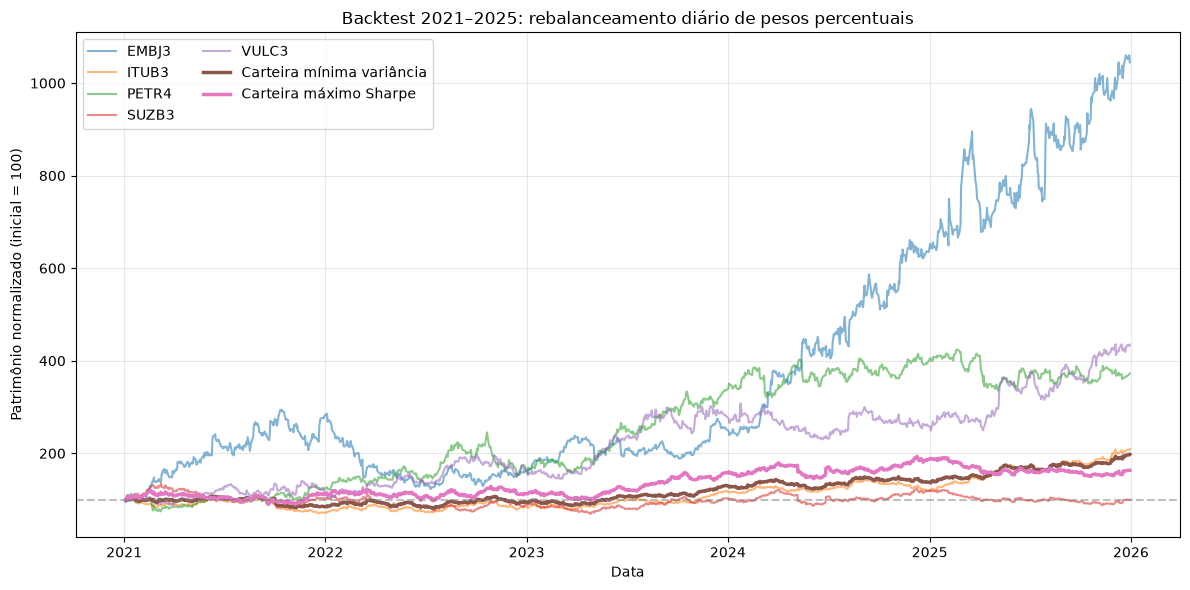

In [107]:
# Implementação atual: pesos percentuais constantes por rebalanceamento diário.
# Os pesos foram estimados uma vez na calibração; não há reotimização no teste.
# A política final continua pendente: buy-and-hold manteria quantidades, não percentuais.
retornos_carteiras_teste = pd.DataFrame(
    {
        "Carteira mínima variância": retornos_teste @ pesos_min_variancia,
        "Carteira máximo Sharpe": retornos_teste @ pesos_max_sharpe,
    },
    index=retornos_teste.index,
)
evolucao_teste_ativos = (1 + retornos_teste).cumprod() * 100
evolucao_teste_carteiras = (1 + retornos_carteiras_teste).cumprod() * 100

plt.figure(figsize=(12, 6))
for ativo in ativos:
    plt.plot(evolucao_teste_ativos.index, evolucao_teste_ativos[ativo], alpha=0.55, label=ativo.replace(".SA", ""))
for carteira in evolucao_teste_carteiras.columns:
    plt.plot(evolucao_teste_carteiras.index, evolucao_teste_carteiras[carteira], linewidth=2.5, label=carteira)
plt.axhline(100, linestyle="--", color="gray", alpha=0.5)
plt.title("Backtest 2021–2025: rebalanceamento diário de pesos percentuais")
plt.xlabel("Data")
plt.ylabel("Patrimônio normalizado (inicial = 100)")
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()


## Backtesting 2021–2025 e comparação com Ibovespa e CDI

Esta seção aplica os pesos congelados ao período de teste, sem usar dados futuros para estimá-los. O cálculo atualmente implementado rebalanceia diariamente para restaurar os pesos percentuais; a escolha final da política ainda precisa ser confirmada. O CDI e o Ibovespa são alinhados às datas em que há retornos comuns.


Período comum: 2021-01-04 a 2025-12-30 | observações: 1244


,Retorno acumulado,CAGR,Volatilidade anualizada,Sharpe (Rf = CDI)
Carteira mínima variância,0.9770,0.1461,0.1867,0.2753
Carteira máximo Sharpe,0.6325,0.1030,0.2275,0.0914
Ibovespa,0.3401,0.0603,0.1776,-0.1645
CDI,0.6733,0.1085,0.0022,NaN


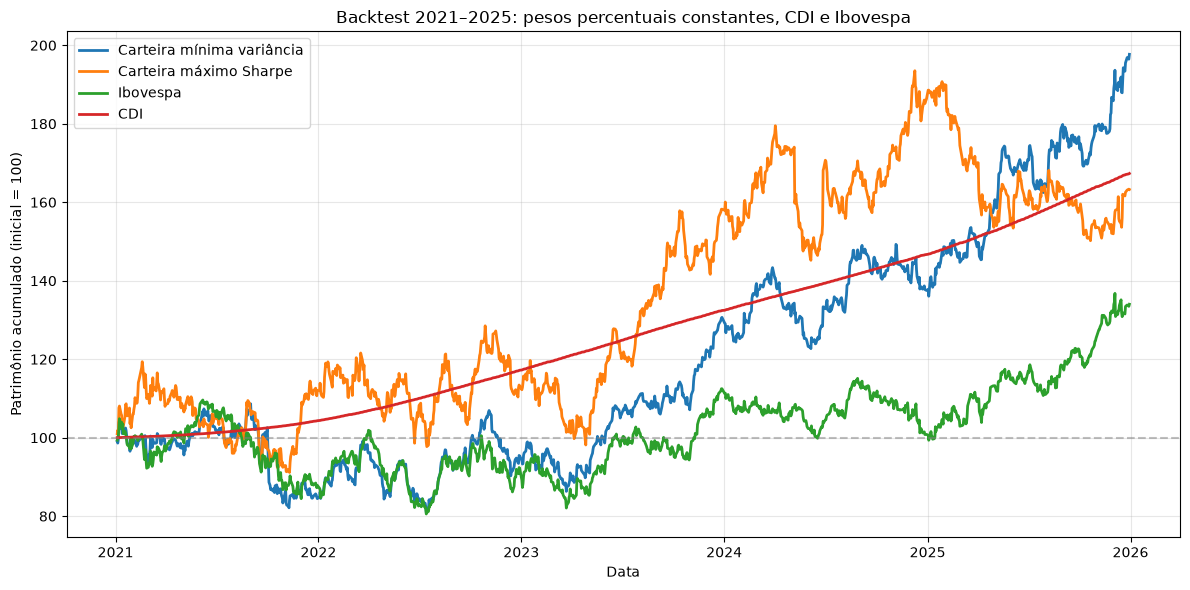

In [108]:
# 4. Comparação do backtest fixo 2021–2025 com Ibovespa e CDI nas mesmas datas.
ibov_download = yf.download("^BVSP", start="2020-12-30", end=data_fim_teste_exclusivo,
    interval="1d", auto_adjust=False, progress=False)
ibov_precos = ibov_download["Adj Close"]
if isinstance(ibov_precos, pd.DataFrame):
    ibov_precos = ibov_precos.iloc[:, 0]
retorno_ibovespa = ibov_precos.pct_change(fill_method=None).rename("Ibovespa")
retorno_cdi_teste = serie_cdi.rename("CDI")
retornos_comparacao = pd.concat([retornos_carteiras_teste, retorno_ibovespa, retorno_cdi_teste], axis=1).loc[
    data_inicio_teste:data_fim_teste_exclusivo].dropna()
if retornos_comparacao.empty:
    raise ValueError("Não há datas em comum entre carteiras, CDI e Ibovespa.")
patrimonio_comparacao = (1 + retornos_comparacao).cumprod() * 100
print("Período comum:", retornos_comparacao.index.min().date(), "a", retornos_comparacao.index.max().date(),
      "| observações:", len(retornos_comparacao))
resumo_comparacao = pd.DataFrame(index=retornos_comparacao.columns)
resumo_comparacao["Retorno acumulado"] = patrimonio_comparacao.iloc[-1] / 100 - 1
data_base_investimento = pd.Timestamp("2020-12-30")  # fechamento anterior ao primeiro retorno de 2021
anos_decorridos = (retornos_comparacao.index[-1] - data_base_investimento).days / 365.25
resumo_comparacao["CAGR"] = (patrimonio_comparacao.iloc[-1] / 100) ** (1 / anos_decorridos) - 1
resumo_comparacao["Volatilidade anualizada"] = retornos_comparacao.std(ddof=1) * np.sqrt(252)
coluna_sharpe = "Sharpe (Rf = CDI)"
resumo_comparacao[coluna_sharpe] = np.nan
for serie in ["Carteira mínima variância", "Carteira máximo Sharpe", "Ibovespa"]:
    excesso = retornos_comparacao[serie] - retornos_comparacao["CDI"]
    desvio_excesso = excesso.std(ddof=1)
    resumo_comparacao.loc[serie, coluna_sharpe] = excesso.mean() / desvio_excesso * np.sqrt(252) if desvio_excesso > 0 else np.nan
display(resumo_comparacao.round(4))
plt.figure(figsize=(12, 6))
for serie in patrimonio_comparacao.columns:
    plt.plot(patrimonio_comparacao.index, patrimonio_comparacao[serie], linewidth=2, label=serie)
plt.axhline(100, linestyle="--", color="gray", alpha=0.5)
plt.title("Backtest 2021–2025: pesos percentuais constantes, CDI e Ibovespa")
plt.xlabel("Data"); plt.ylabel("Patrimônio acumulado (inicial = 100)")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()


## Interpretação, estado do projeto e limitações

- A amostra usada na otimização é 03/01/2018–30/12/2020 (739 retornos completos). O teste começa em 2021 e termina em 2025; não há sobreposição temporal entre estimação e avaliação.
- `retorno_medio_diario`, `matriz_covariancia_diaria`, `pesos_min_variancia`, `resultado_min_variancia`, `pesos_max_sharpe` e `resultado_max_sharpe` são os objetos usados na análise definitiva. Execute o notebook de cima para baixo para que cada resultado venha da mesma janela. As variáveis `Sigma` e `mu` das células de experimento foram removidas da seção definitiva por serem aliases redefinidos depois da otimização.
- O Sharpe de calibração usa retorno esperado anualizado menos CDI médio diário × 252, dividido pela volatilidade anualizada. No backtest, Sharpe ex-post usa retorno da carteira menos CDI diário nas mesmas datas; CDI não recebe Sharpe contra si próprio.
- `Adj Close` é proxy de retorno total do Yahoo e pode incorporar ajustes societários. Não se confirmou a origem dos saltos antigos de SUZB3/VULC3. Custos, tributos, spread, impacto de mercado e liquidez negociável não estão modelados.
- Etapas ainda abertas: critérios e tabela de triagem; escolher duas empresas e premissas para DDM e FCFF/WACC; confirmar a política de rebalanceamento; interpretar os resultados no relatório técnico. Nenhuma hipótese de valuation foi criada neste notebook.
